In [1]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [2]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    if (argc < 2) {
        std::cerr << "Usage: ./detect_faces <image_path>" << std::endl;
        return 1;
    }
    std::string source = argv[1];

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
        1.05,
        5,
        0,
        cv::Size(20, 20)
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;

    int total_eyes = 0;
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        total_eyes += eyes.size();
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    std::cout << "Detected eyes: " << total_eyes << std::endl;
    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 2;
    }
    return 0;
}

Writing detect_faces.cpp


In [3]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

### Эксперимент 1: Групповое фото

In [4]:
from google.colab import files
from PIL import Image

uploaded = files.upload()
fname = list(uploaded.keys())[0]
Image.open(fname).convert("RGB").save("photo1.jpg", "JPEG")

Saving group-people-funny-young-gray-background-60465988.webp to group-people-funny-young-gray-background-60465988.webp


In [5]:
!./detect_faces photo1.jpg

Loading: photo1.jpg
Image: 800x565
Detected faces: 5
Detected eyes: 1
Result saved: faces_detected.jpg


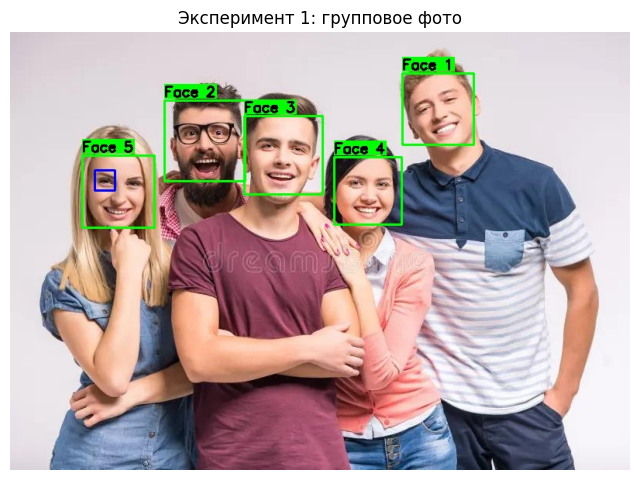

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open('faces_detected.jpg')
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 1: групповое фото')
plt.axis('off')
plt.show()

### Эксперимент 2: Фото в профиль

In [13]:
from google.colab import files
from PIL import Image

uploaded = files.upload()
fname = list(uploaded.keys())[0]
Image.open(fname).convert("RGB").save("photo2.jpg", "JPEG")

Saving side profile.webp to side profile.webp


In [14]:
!./detect_faces photo2.jpg

Loading: photo2.jpg
Image: 800x681
Detected faces: 2
Detected eyes: 0
Result saved: faces_detected.jpg


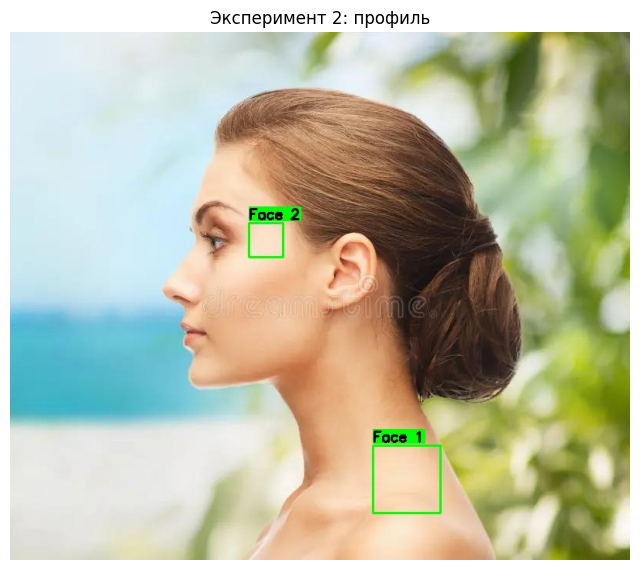

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open('faces_detected.jpg')
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 2: профиль')
plt.axis('off')
plt.show()

### Эксперимент 3: Одиночный портрет анфас

In [10]:
from google.colab import files
from PIL import Image

uploaded = files.upload()
fname = list(uploaded.keys())[0]
Image.open(fname).convert("RGB").save("photo3.jpg", "JPEG")

Saving brand_minds_2020_six_principles_business_ethics-min-2048x1365.webp to brand_minds_2020_six_principles_business_ethics-min-2048x1365.webp


In [11]:
!./detect_faces photo3.jpg

Loading: photo3.jpg
Image: 2048x1365
Detected faces: 5
Detected eyes: 2
Result saved: faces_detected.jpg


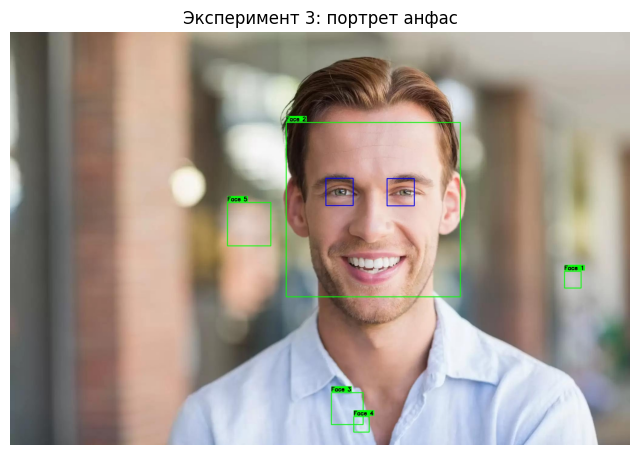

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open('faces_detected.jpg')
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title('Эксперимент 3: портрет анфас')
plt.axis('off')
plt.show()

###Выводы

| Эксперимент | Лиц на фото (факт) | Распознано лиц (алгоритм) | Глаз на фото (факт) | Распознано глаз (алгоритм) |
| :--- | :---: | :---: | :---: | :---: |
| **Эксперимент 1** (Группа из 5 человек) | **5** | **5** | **10** | **1** |
| **Эксперимент 2** (Девушка в профиль) | **1** | **2** *(оба ложные)* | **1** | **0** |
| **Эксперимент 3** (Мужчина анфас) | **1** | **5** *(1 верное + 4 ложных)* | **2** | **2** |

#### Причины расхождений:
1. **Эксперимент 1 (Групповое фото — 5 лиц из 5, 1 глаз из 10):** Все 5 лиц найдены верно благодаря однородному светлому фону. Однако распознан только один глаз у девушки слева: на групповом снимке лица занимают мало пикселей, параметр `minNeighbors = 10` для глаз слишком строгий, у мужчины в очках оправа перекрывает перепады яркости вокруг глаз, а у остальных глаза прищурены из-за улыбок.
2. **Эксперимент 2 (Девушка в профиль — 0 настоящих лиц, 2 ложных срабатывания и 0 глаз):** Стандартный каскад `haarcascade_frontalface_default.xml` обучен исключительно на фронтальных лицах (анфас) и не распознаёт профиль. Из-за высокой чувствительности (`scaleFactor = 1.05`, `minSize = 20x20`) и выравнивания гистограммы (`cv::equalizeHist`) случайные тени на плече и виске вызвали ложные срабатывания.
3. **Эксперимент 3 (Мужчина анфас — 1 настоящее лицо, 4 ложных срабатывания и 2 глаза):** Основное лицо и оба глаза найдены точно. Четыре лишние рамки на воротнике рубашки и в размытых пятнах фона возникли из-за высокого разрешения снимка и маленького минимального окна поиска (`20x20`), которое реагирует на мелкие контрастные текстуры.

**Вывод:** Каскады Хаара хорошо работают на фронтальных портретах, но не видят профиль и чувствительны к выбору параметров масштабирования и минимального размера окна поиска.